# Land-cover segmentation on aerial imagery

The 40-epoch U-Net trained on a Colab L4 is compared with the saved Random Forest and
majority-class baselines. The models segment the same 16 aerial tiles in the
`D017-2021` development batch.

The outputs are saved below. To rerun the demo, start JupyterLab from the project
root with the command below, then choose **Run All Cells**. The cells load the three
saved runs from `runs/` and the validation GeoTIFFs from `data/raw/D017-2021/`.

```sh
uv run --locked --group nn --group demo jupyter lab notebooks/landcover-model-demo.ipynb
```

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.patches import Patch

%matplotlib inline

current = Path.cwd()
root = next(
    (folder for folder in (current, *current.parents)
     if (folder / "src/landcover/models.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open the notebook from inside the project checkout.")
sys.path.insert(0, str(root / "src"))

In [2]:
from landcover import models
from landcover.pipeline import IGNORE, batch_dir, extract
from landcover.train import sha256

run_paths = {
    "Majority class": root / "runs/rule-07c41af",
    "Random Forest": root / "runs/rf-07c41af",
    "U-Net · Colab L4": root / "runs/unet-c1f77a3",
}
records = {
    name: json.loads((path / "run.json").read_text())
    for name, path in run_paths.items()
}
unet_name = "U-Net · Colab L4"
unet_run = records[unet_name]
assert all(
    record["data_version"] == unet_run["data_version"]
    and record["batches"]["dev"] == unet_run["batches"]["dev"]
    for record in records.values()
)

(batch_id,) = unet_run["batches"]["dev"]
tile_ids = extract(batch_dir(batch_id))
if not tile_ids:
    raise FileNotFoundError(f"Validation GeoTIFFs are missing for {batch_id}.")
tiles = models.load_tiles([batch_id])

device = models.pick_device()
predictors = {}
for name, path in run_paths.items():
    record = records[name]
    model_file = path / record["model_file"]
    assert sha256(model_file) == record["model_sha256"], model_file
    predictors[name] = models.load_predictor(record["model"], model_file, device)

print(f"{batch_id} · {len(tiles)} tiles · U-Net inference on {device}")

D017-2021 · 16 tiles · U-Net inference on mps


## Validation scores

mIoU averages the overlap between predicted and reference regions across the six
labelled land-cover classes. The scores pool pixels across the full development
batch. Unlabelled pixels are excluded.

In [3]:
examples = []
for tile_id, (rgb, reference) in zip(tile_ids, tiles, strict=True):
    predictions = {name: predict(rgb) for name, predict in predictors.items()}
    accuracies = {}
    for name, mask in predictions.items():
        counts = models.confusion(reference, mask)
        accuracies[name] = counts.trace() / counts.sum()
    examples.append((tile_id, rgb, reference, predictions, accuracies))

scores = {
    name: models.evaluate_masks(
        (reference, predictions[name]) for _, _, reference, predictions, _ in examples
    )[0]
    for name in predictors
}
table = [
    "| Model | Saved run | mIoU | Pixel accuracy |",
    "| :-- | :-- | --: | --: |",
]
for name, score in scores.items():
    table.append(
        f"| {name} | `{run_paths[name].name}` | "
        f"{score['miou']:.2%} | {score['pixel_accuracy']:.2%} |"
    )
display(Markdown("\n".join(table)))

| Model | Saved run | mIoU | Pixel accuracy |
| :-- | :-- | --: | --: |
| Majority class | `rule-07c41af` | 4.56% | 27.35% |
| Random Forest | `rf-07c41af` | 14.78% | 25.58% |
| U-Net · Colab L4 | `unet-c1f77a3` | 33.55% | 43.40% |

## Side-by-side predictions

The examples come from the lower, middle and upper parts of the U-Net's tile
accuracy ranking. Each panel in the bottom row reports the percentage of labelled
pixels that the corresponding model classified correctly on that tile. Grey pixels
in the reference mask are excluded from scoring.

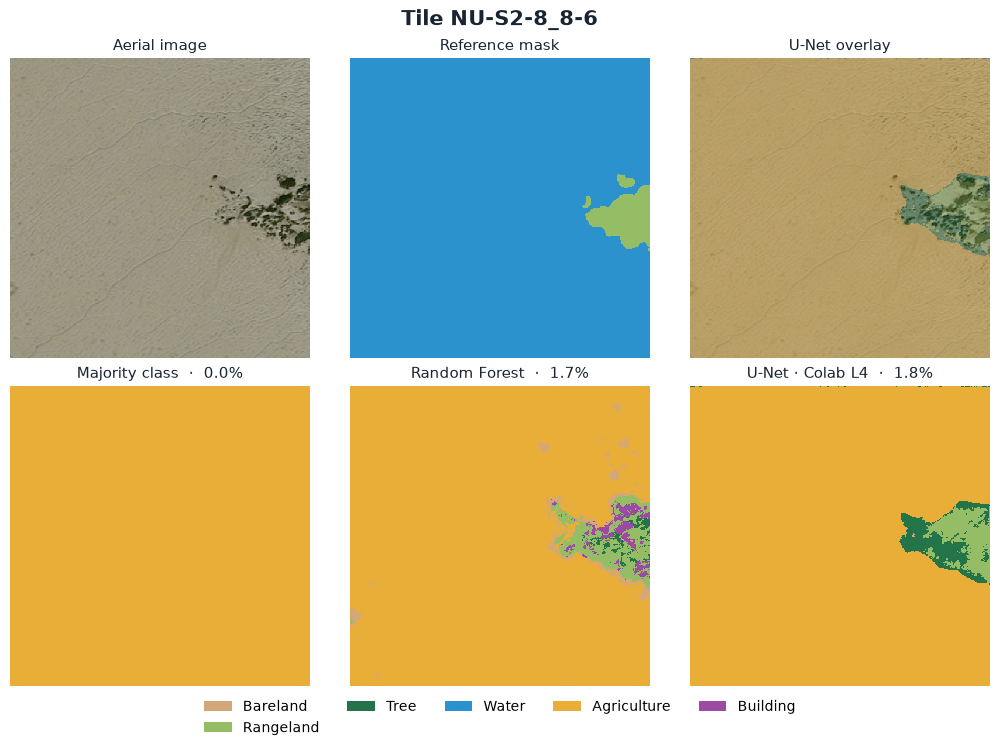

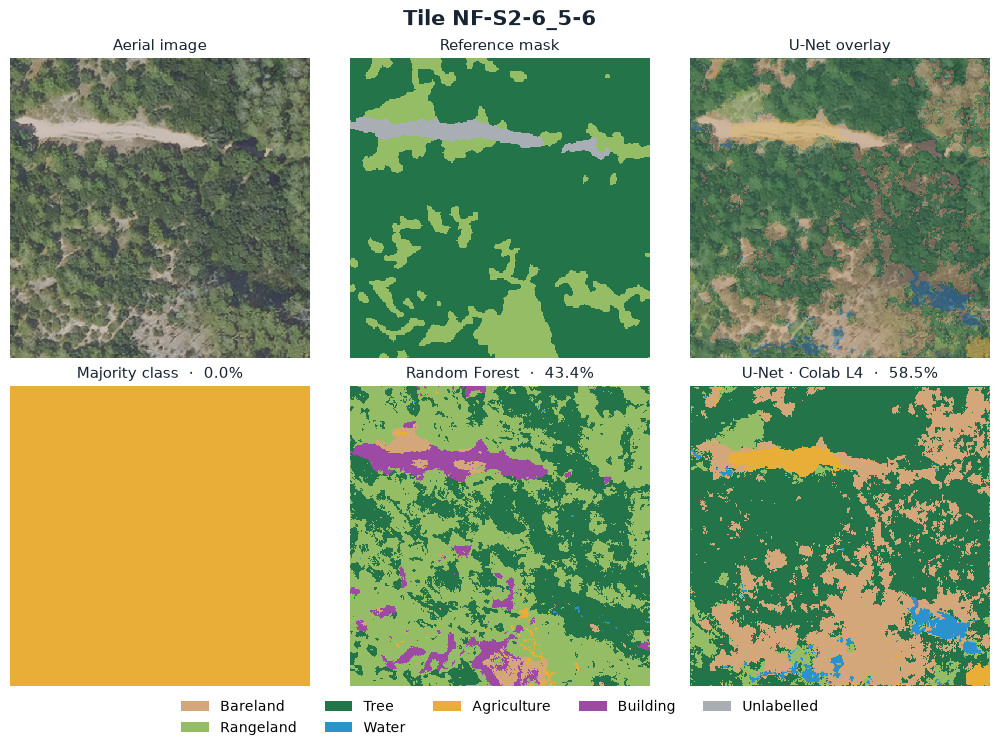

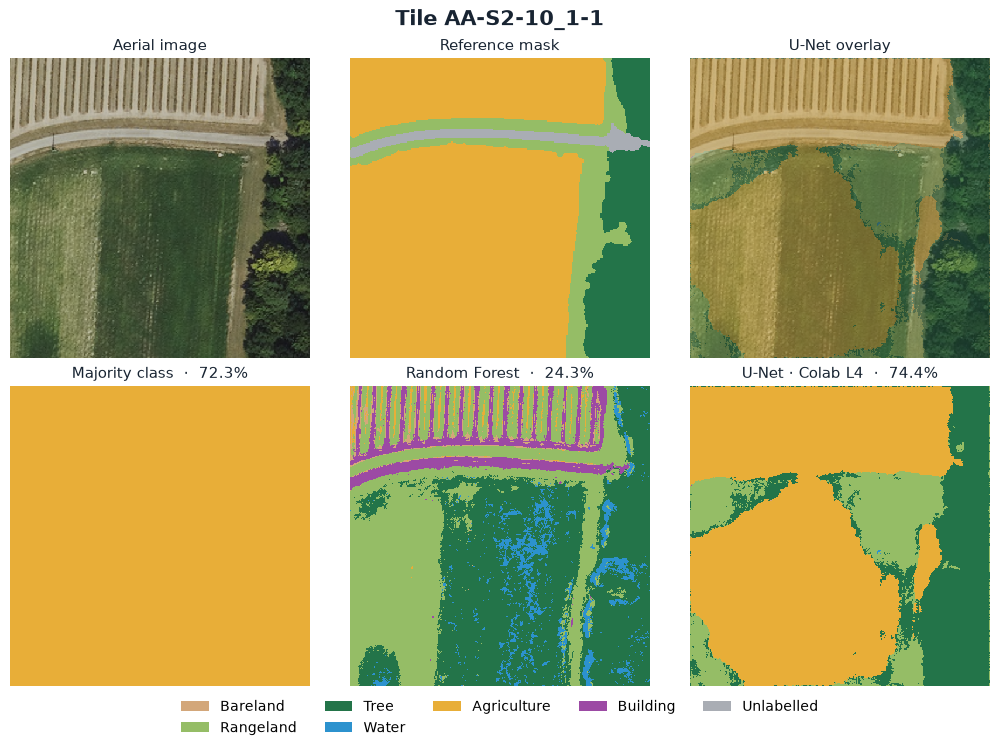

In [4]:
class_colors = [
    "#d3a77a", "#95bd66", "#9b7180", "#32384c",
    "#237449", "#2c92ce", "#e8ae38", "#9c4aa4",
]
ignore_color = "#a9adb4"
palette = np.zeros((256, 3), dtype=np.uint8)
for class_id, color in enumerate(class_colors):
    palette[class_id] = [int(color[i:i + 2], 16) for i in (1, 3, 5)]
palette[IGNORE] = [int(ignore_color[i:i + 2], 16) for i in (1, 3, 5)]

ranked = sorted(examples, key=lambda example: example[4][unet_name])
ranks = [round((len(ranked) - 1) * fraction) for fraction in (0.2, 0.5, 0.8)]
for rank in ranks:
    tile_id, rgb, reference, predictions, accuracies = ranked[rank]
    overlay = (0.63 * rgb + 0.37 * palette[predictions[unet_name]]).astype(np.uint8)
    panels = [
        ("Aerial image", rgb),
        ("Reference mask", palette[reference]),
        ("U-Net overlay", overlay),
        *[
            (f"{name}  ·  {accuracies[name]:.1%}", palette[mask])
            for name, mask in predictions.items()
        ],
    ]

    figure, axes = plt.subplots(2, 3, figsize=(10.2, 7.4), layout="constrained")
    figure.suptitle(f"Tile {tile_id}", fontsize=15, fontweight="bold", color="#182432")
    for axis, (title, pixels) in zip(axes.flat, panels, strict=True):
        axis.imshow(pixels, interpolation="nearest")
        axis.set_title(title, fontsize=11, color="#182432")
        axis.set_axis_off()

    present = set(np.unique(reference))
    for mask in predictions.values():
        present.update(np.unique(mask))
    legend = [
        Patch(facecolor=class_colors[i], label=label.capitalize())
        for i, label in enumerate(models.CLASS_NAMES)
        if i in present
    ]
    if IGNORE in present:
        legend.append(Patch(facecolor=ignore_color, label="Unlabelled"))
    figure.legend(handles=legend, loc="outside lower center", ncols=5, frameon=False)
    plt.show()